# Práctica 3: Clasificadores Bayesianos
## Parte II — Breast Cancer Wisconsin

Se sigue exactamente el orden de la práctica: carga de datos, división estratificada, estandarización, entrenamiento de QDA/LDA/GNB, métricas, matrices de confusión y análisis.

In [ ]:
# LIBRERÍAS
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis, LinearDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, classification_report

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


## a) Carga de datos mediante `load_breast_cancer`

In [ ]:
# a) CARGA
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="Clase")

print("Ejemplos:", X.shape[0])
print("Características:", X.shape[1])
print("Clases:", dict(enumerate(data.target_names)))
display(X.head())

Ejemplos: 569
Características: 30
Clases: {0: np.str_('malignant'), 1: np.str_('benign')}


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Distribución de clases:


,count
Clase,
0,212
1,357


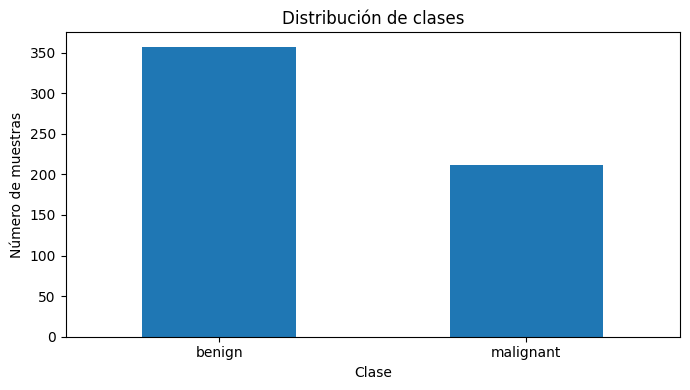

In [ ]:
print("Distribución de clases:")
display(y.value_counts().sort_index())

plt.figure(figsize=(7,4))
y.map({0:data.target_names[0],1:data.target_names[1]}).value_counts().plot(kind="bar")
plt.xlabel("Clase")
plt.ylabel("Número de muestras")
plt.title("Distribución de clases")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## b) `train_test_split` con `stratify` y estandarización

In [ ]:
# b) TRAIN / TEST ESTRATIFICADO
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

print("\nProporciones en train:")
print(y_train.value_counts(normalize=True).sort_index())

print("\nProporciones en test:")
print(y_test.value_counts(normalize=True).sort_index())

Train: (455, 30)
Test: (114, 30)

Proporciones en train:
Clase
0    0.373626
1    0.626374
Name: proportion, dtype: float64

Proporciones en test:
Clase
0    0.368421
1    0.631579
Name: proportion, dtype: float64


In [ ]:
# b) ESTANDARIZACIÓN
scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train)
X_test_std = scaler.transform(X_test)

print("Datos estandarizados correctamente.")

Datos estandarizados correctamente.


## c) Entrenamiento de QDA, LDA y GNB

In [ ]:
# c) ENTRENAMIENTO
modelos = {
    "QDA": QuadraticDiscriminantAnalysis(reg_param=0.01),
    "LDA": LinearDiscriminantAnalysis(),
    "GNB": GaussianNB()
}

for nombre, modelo in modelos.items():
    modelo.fit(X_train_std, y_train)
    print(nombre, "entrenado.")

QDA entrenado.
LDA entrenado.
GNB entrenado.


## d) Accuracy, precision, recall y matriz de confusión

In [ ]:
# d) MÉTRICAS
resultados = {}
predicciones = {}

for nombre, modelo in modelos.items():
    y_pred = modelo.predict(X_test_std)
    predicciones[nombre] = y_pred

    precision = precision_score(y_test, y_pred, average=None, zero_division=0)
    recall = recall_score(y_test, y_pred, average=None, zero_division=0)
    accuracy = accuracy_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)

    resultados[nombre] = {
        "accuracy": accuracy,
        "precision_clase_0": precision[0],
        "precision_clase_1": precision[1],
        "recall_clase_0": recall[0],
        "recall_clase_1": recall[1]
    }

    print("="*70)
    print(nombre)
    print("="*70)
    print(f"Accuracy: {accuracy:.4f}")
    print("\nPrecision:")
    for i,v in enumerate(precision):
        print(f"  {data.target_names[i]}: {v:.4f}")
    print("\nRecall:")
    for i,v in enumerate(recall):
        print(f"  {data.target_names[i]}: {v:.4f}")
    print("\nReporte:")
    print(classification_report(
        y_test, y_pred,
        target_names=data.target_names,
        zero_division=0
    ))
    print("Matriz de confusión:")
    print(cm)

QDA
Accuracy: 0.9561

Precision:
  malignant: 0.9744
  benign: 0.9467

Recall:
  malignant: 0.9048
  benign: 0.9861

Reporte:
              precision    recall  f1-score   support

   malignant       0.97      0.90      0.94        42
      benign       0.95      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114

Matriz de confusión:
[[38  4]
 [ 1 71]]
LDA
Accuracy: 0.9561

Precision:
  malignant: 0.9744
  benign: 0.9467

Recall:
  malignant: 0.9048
  benign: 0.9861

Reporte:
              precision    recall  f1-score   support

   malignant       0.97      0.90      0.94        42
      benign       0.95      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114

Matriz de confusión:
[[38  4]
 [ 1 71]]
GNB
Accuracy: 

In [ ]:
# TABLA COMPARATIVA
resultados_df = pd.DataFrame(resultados).T
display(resultados_df.round(4))

,accuracy,precision_clase_0,precision_clase_1,recall_clase_0,recall_clase_1
QDA,0.9561,0.9744,0.9467,0.9048,0.9861
LDA,0.9561,0.9744,0.9467,0.9048,0.9861
GNB,0.9298,0.9048,0.9444,0.9048,0.9444


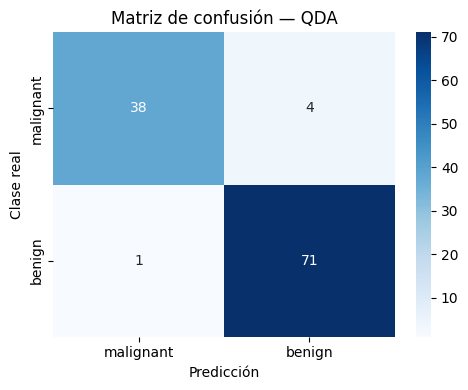

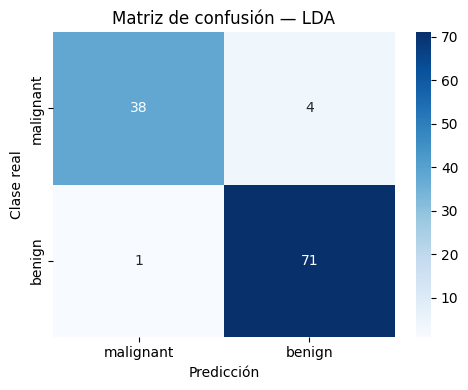

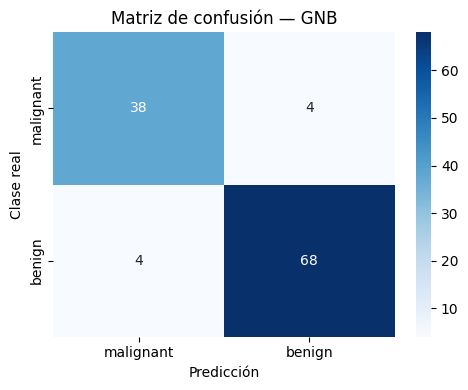

In [ ]:
# MATRICES DE CONFUSIÓN
for nombre, y_pred in predicciones.items():
    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5,4))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=data.target_names,
        yticklabels=data.target_names
    )
    plt.xlabel("Predicción")
    plt.ylabel("Clase real")
    plt.title(f"Matriz de confusión — {nombre}")
    plt.tight_layout()
    plt.show()

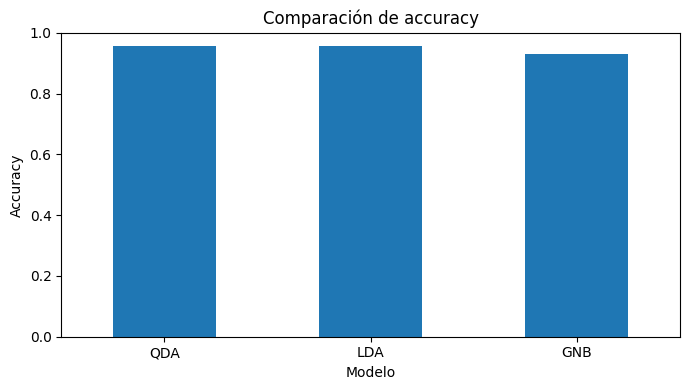

In [ ]:
# COMPARACIÓN DE ACCURACY
plt.figure(figsize=(7,4))
resultados_df["accuracy"].plot(kind="bar")
plt.ylim(0,1)
plt.ylabel("Accuracy")
plt.xlabel("Modelo")
plt.title("Comparación de accuracy")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## e) Análisis
1. ¿Cuál tiene mayor accuracy?QDA y LDA obtuvieron la mayor accuracy, con 95.61 % cada uno. GNB obtuvo una accuracy de 92.98 %, por lo que su desempeño general fue ligeramente inferior.
2. ¿Cuál tiene mejor precision por clase?
QDA y LDA obtuvieron los mejores resultados de precision en ambas clases. Para la clase maligna, ambos alcanzaron 97.44 %, mientras que GNB obtuvo 90.48 %. Para la clase benigna, QDA y LDA alcanzaron 94.67 %, frente al 94.44 % de GNB.
3. ¿Cuál tiene mejor recall por clase?
Para la clase maligna, los tres modelos obtuvieron el mismo recall de 90.48 %, por lo que ninguno fue superior en la detección de casos malignos. Para la clase benigna, QDA y LDA obtuvieron el mejor resultado, con 98.61 %, mientras que GNB obtuvo 94.44 %.
4. ¿Dónde se concentran los errores?
En QDA y LDA se obtuvieron 4 falsos negativos, es decir, 4 casos malignos fueron clasificados como benignos, y 1 falso positivo, correspondiente a un caso benigno clasificado como maligno. En GNB también hubo 4 falsos negativos, pero aumentaron los falsos positivos a 4. Debido a que se trata de detección de cáncer, los falsos negativos son especialmente importantes, ya que implican no detectar un caso maligno. Por ello, en este tipo de aplicación normalmente se busca minimizar los falsos negativos, aunque esto pueda generar más falsos positivos.
5. ¿Qué diferencias se observan entre QDA, LDA y GNB?
QDA y LDA presentaron exactamente el mismo desempeño en esta prueba, con 95.61 % de accuracy y las mismas métricas y matriz de confusión. Sin embargo, existe una diferencia en sus supuestos: LDA utiliza una matriz de covarianza común para todas las clases, mientras que QDA utiliza una matriz de covarianza independiente para cada clase. Esto hace que QDA sea más flexible y pueda representar diferentes formas de distribución para cada clase, aunque en este caso dicha flexibilidad no produjo una mejora respecto a LDA. GNB, por su parte, asume independencia entre las características y obtuvo el menor desempeño general, con 92.98 % de accuracy. Por lo tanto, para estos resultados, QDA y LDA fueron los mejores modelos, aunque LDA podría preferirse por su modelo más simple si ambos mantienen el mismo desempeño, mientras que QDA puede ser conveniente cuando las clases presentan covarianzas diferentes.


## f) Recomendación       

Se recomienda LDA, ya que obtuvo una accuracy de 95.61 %, igual que QDA y superior a GNB (92.98 %). Además, LDA y QDA tuvieron los mismos valores de precision, recall y matriz de confusión. Por ello, se elige LDA por ser más simple, sin perder rendimiento en esta prueba.  
Aunque QDA permite una matriz de covarianza diferente para cada clase, esta mayor flexibilidad no generó una mejora en los resultados obtenidos. Para otras aplicaciones, la elección dependería principalmente del costo de los errores, el recall de la clase de interés, la distribución de los datos y si las clases presentan covarianzas diferentes.

In [ ]:
# RESUMEN AUTOMÁTICO
mejor = resultados_df["accuracy"].idxmax()
print("Modelo con mayor accuracy:", mejor)
print(f"Accuracy: {resultados_df.loc[mejor, 'accuracy']:.4f}")
display(resultados_df.round(4))

Modelo con mayor accuracy: QDA
Accuracy: 0.9561


,accuracy,precision_clase_0,precision_clase_1,recall_clase_0,recall_clase_1
QDA,0.9561,0.9744,0.9467,0.9048,0.9861
LDA,0.9561,0.9744,0.9467,0.9048,0.9861
GNB,0.9298,0.9048,0.9444,0.9048,0.9444
